# 8. Coalescence and sintering of viscous drops

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1–3 and 5; Chapter 7 is helpful

Two drops of a very viscous liquid touch. A neck forms where they meet, it widens,
and after a while the pair has become one round drop. The same process joins the
grains of a polymer powder when it is melted in a mould, the filaments laid down by
a 3D printer, and the particles of a glass powder in a furnace. It is called
*sintering* when the drops are particles of a solid that flows only slowly at high
temperature. Surface tension drives it, because one drop has less surface than two,
and viscosity resists it.

The problem looks like those of Chapters 6 and 7, with one variable (the width of
the neck) and two functions. It differs in one respect. The flow now fills the
whole drop and has no thin-film geometry to make it simple, and the shape changes
completely. A trial solution therefore needs two parts: a family of shapes, and a
velocity field that carries one shape of the family into the next. The chapter is
about what happens when these two parts do not fit together.

There is one exact solution: Hopper's, for two equal cylinders (a problem in two
dimensions). We use it to check two trial solutions. The first is the model that
Frenkel proposed in 1945, still the starting point of many models of sintering.
The second keeps the correct shapes and uses the simplest flow that fits them.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq
from scipy.special import ellipk

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 8.1 The problem

Two long cylinders of radius $a_0$, made of a liquid of viscosity $\eta$ and
surface tension $\gamma$, lie side by side and touch along a line. Everything
happens in the plane perpendicular to their axes, so the problem is two-dimensional:
two discs of radius $a_0$ become one disc. Inertia is negligible, as it is for any
liquid viscous enough to be called a melt (Exercise 4 gives numbers), and there is
no outer fluid.

*Conservation.* The liquid is incompressible, so the area of the cross-section stays
$2\pi a_0^2$, and the final disc has the radius $R_f = \sqrt2\,a_0$.

*Free energy.* Per unit length of the cylinders,

$$ A = \gamma P , \tag{8.1} $$

where $P$ is the perimeter of the cross-section. It falls from $4\pi a_0$ to
$2\sqrt2\,\pi a_0$.

*Scales.* The only time that can be formed from $\eta$, $\gamma$ and $a_0$ is

$$ \tau = \frac{\eta\,a_0}{\gamma} . \tag{8.2} $$

Lengths below are in units of $a_0$ and times in units of $\tau$. The cell below
gives $\tau$ for a polymer melt and for a glass at its softening point, where the
viscosity is $10^{6.6}$ Pa s by definition.

In [2]:
cases = [("polymer melt, 0.2 mm grains", 1.0e3, 0.03, 0.2e-3),
         ("glass at its softening point, 50 um grains", 10**6.6, 0.3, 50e-6)]
for name, viscosity, tension, radius in cases:
    print(f"{name:44s}  tau = eta a0 / gamma = {viscosity * radius / tension:7.1f} s")

polymer melt, 0.2 mm grains                   tau = eta a0 / gamma =     6.7 s
glass at its softening point, 50 um grains    tau = eta a0 / gamma =   663.5 s


## 8.2 Frenkel's model

*Shapes.* Frenkel (1945) let each of two spheres keep its shape, cut off by the
plane of the neck. In two dimensions each drop is then a circle cut off by the
neck. Let $a$ be the radius of the two circles and $\theta$ the angle
that the neck subtends at the centre of each, so that the centres are at the distance
$a\cos\theta$ from the neck and the neck has the half-width

$$ x = a\sin\theta . $$

The area of each truncated circle is $a^2(\pi - \theta + \sin\theta\cos\theta)$,
and setting it equal to $\pi a_0^2$ fixes $a$:

$$ a(\theta) = a_0\Big(\frac{\pi}{\pi - \theta + \sin\theta\cos\theta}\Big)^{1/2} , \qquad P(\theta) = 4a(\pi - \theta) . \tag{8.3} $$

The circles grow slightly as they merge, to keep the area. At $\theta = \pi/2$ the
two halves form the final disc. The angle $\theta$ is the slow variable.

*Flow.* Frenkel assumed the simplest flow: a uniform compression along the line of
centres (the $X$ axis), with an equal extension across it,

$$ v_X = \dot\epsilon\,X , \qquad v_Y = -\dot\epsilon\,Y , $$

which is incompressible. The rate of strain $\dot\epsilon$ is uniform, the
dissipation per unit area is $4\eta\dot\epsilon^2$, and

$$ \Phi = \tfrac12\times4\eta\dot\epsilon^2\times2\pi a_0^2 = 4\pi\eta a_0^2\,\dot\epsilon^2 . \tag{8.4} $$

*The link between shape and flow.* A uniform compression does not carry a truncated
circle into another truncated circle: it turns a circle into an ellipse. The flow
cannot follow the shapes everywhere, and one has to decide where it should. The
natural choice is the two far ends of the pair, at $X = \pm L$ with
$L = a(1 + \cos\theta)$, which then move as the flow moves them:

$$ \dot\epsilon = \frac{\dot L}{L} = \frac{d\ln L}{d\theta}\,\dot\theta . \tag{8.5} $$

*Minimise.* With Eqs. (8.1), (8.4) and (8.5), the Rayleighian is a function of
$\dot\theta$, and its minimum is at

$$ \dot\theta = -\frac{\gamma\,dP/d\theta}{8\pi\eta a_0^2\,(d\ln L/d\theta)^2} . \tag{8.6} $$

For a small neck, $dP/d\theta \to -4a_0$ (each of the two notches at the neck loses
the length $2\,dx$) and $d\ln L/d\theta \to -\theta/2$, so that
$\theta^2\dot\theta = 2\gamma/\pi\eta a_0$ and

$$ \frac{x}{a_0} \simeq \theta = \Big(\frac{6}{\pi}\,\frac{t}{\tau}\Big)^{1/3} . \tag{8.7} $$

The neck grows as the cube root of the time, with an infinite speed at the start.
The cell below derives these results.

In [3]:
th, a0, gam, eta = sp.symbols("theta a_0 gamma eta", positive=True)
a = a0 * sp.sqrt(sp.pi / (sp.pi - th + sp.sin(th) * sp.cos(th)))
P = 4 * a * (sp.pi - th)
L = a * (1 + sp.cos(th))
print("area of a truncated circle:", sp.simplify(a**2 * (sp.pi - th + sp.sin(th) * sp.cos(th))))
print("final state, theta = pi/2:  a =", sp.simplify(a.subs(th, sp.pi / 2)), "  P =", sp.simplify(P.subs(th, sp.pi / 2)))
print("small theta:  dP/dtheta =", sp.series(sp.diff(P, th), th, 0, 2).removeO(),
      "  dlnL/dtheta =", sp.series(sp.diff(sp.log(L), th), th, 0, 2).removeO())

thdot = sp.symbols("thetadot")
Phi_F = 4 * sp.pi * eta * a0**2 * (sp.diff(sp.log(L), th) * thdot) ** 2
rate = on.kinetic_equations(gam * P, Phi_F, [th], [thdot])[thdot]
print("small theta:  theta^2 * thetadot =", sp.limit(th**2 * rate, th, 0))

area of a truncated circle: pi*a_0**2
final state, theta = pi/2:  a = sqrt(2)*a_0   P = 2*sqrt(2)*pi*a_0


small theta:  dP/dtheta = -4*a_0   dlnL/dtheta = -theta/2


small theta:  theta^2 * thetadot = 2*gamma/(pi*a_0*eta)


*The choice in Eq. (8.5) is not unique.* One could as well require the flow to move
the centres of the two circles correctly, or to change the second moments of the
area at the right rate, which is what a uniform strain does to any shape. Each
choice gives its own model. The cell below integrates all three; Figure 8.1(b)
shows the result. The three answers differ by factors of two or more in the time
at which a given neck is reached. This is the first sign that something is wrong:
a trial solution whose flow fits its shapes leaves no such choice.

In [4]:
def frenkel_geometry(theta):
    """Radius, distance of the centres from the neck, neck half-width, half-length, perimeter."""
    radius = math.sqrt(math.pi / (math.pi - theta + math.sin(theta) * math.cos(theta)))
    return radius, radius * math.cos(theta), radius * math.sin(theta), radius * (1 + math.cos(theta)), 4 * radius * (math.pi - theta)

def second_moments(theta):
    """Second moments of the area of the pair along (XX) and across (YY) the line of centres."""
    radius, centre = frenkel_geometry(theta)[:2]
    half_width2 = lambda X: max(radius**2 - (X - centre) ** 2, 0.0)
    XX = 2 * quad(lambda X: X**2 * 2 * math.sqrt(half_width2(X)), 0, centre + radius)[0]
    YY = 2 * quad(lambda X: (2 / 3) * half_width2(X) ** 1.5, 0, centre + radius)[0]
    return XX, YY

def derivative(f, x, h=1e-6):
    return (f(x + h) - f(x - h)) / (2 * h)

def frenkel_rate(theta, tie):
    """Eq. (8.6) with the strain rate tied to the far ends, the centres or the second moments."""
    dP = derivative(lambda s: frenkel_geometry(s)[4], theta)
    if tie == "ends":
        e = derivative(lambda s: frenkel_geometry(s)[3], theta) / frenkel_geometry(theta)[3]
    elif tie == "centres":
        e = derivative(lambda s: frenkel_geometry(s)[1], theta) / frenkel_geometry(theta)[1]
    else:   # a uniform strain changes XX - YY at the rate 2 * strain rate * (XX + YY)
        XX, YY = second_moments(theta)
        e = derivative(lambda s: np.subtract(*second_moments(s)), theta) / (2 * (XX + YY))
    return -dP / (8 * math.pi * e**2)

times = np.logspace(-6, np.log10(8.0), 141)
frenkel = {}
for tie in ("ends", "centres", "moments"):
    sol = solve_ivp(lambda t, y: [frenkel_rate(y[0], tie)], (0, times[-1]), [1e-3], t_eval=times,
                    rtol=1e-9, atol=1e-12, method="LSODA")
    geometry = np.array([frenkel_geometry(theta) for theta in sol.y[0]])
    frenkel[tie] = dict(theta=sol.y[0], neck=geometry[:, 2], length=geometry[:, 3], perimeter=geometry[:, 4])

print("neck half-width x/a0 at t/tau =      0.01     0.1      1       4")
for tie, model in frenkel.items():
    print(f"  Frenkel, tied to the {tie:8s}  " + "  ".join(f"{v:6.3f}" for v in np.interp([0.01, 0.1, 1, 4], times, model["neck"])))
k = 10
print(f"\nEq. (8.7) at t = {times[k]:.2e}: {(6 * times[k] / math.pi) ** (1 / 3):.4f};  numerical theta: {frenkel['ends']['theta'][k]:.4f}")

neck half-width x/a0 at t/tau =      0.01     0.1      1       4
  Frenkel, tied to the ends       0.286   0.634   1.222   1.408
  Frenkel, tied to the centres    0.171   0.362   0.694   0.921
  Frenkel, tied to the moments    0.234   0.526   1.102   1.388

Eq. (8.7) at t = 3.11e-06: 0.0181;  numerical theta: 0.0182


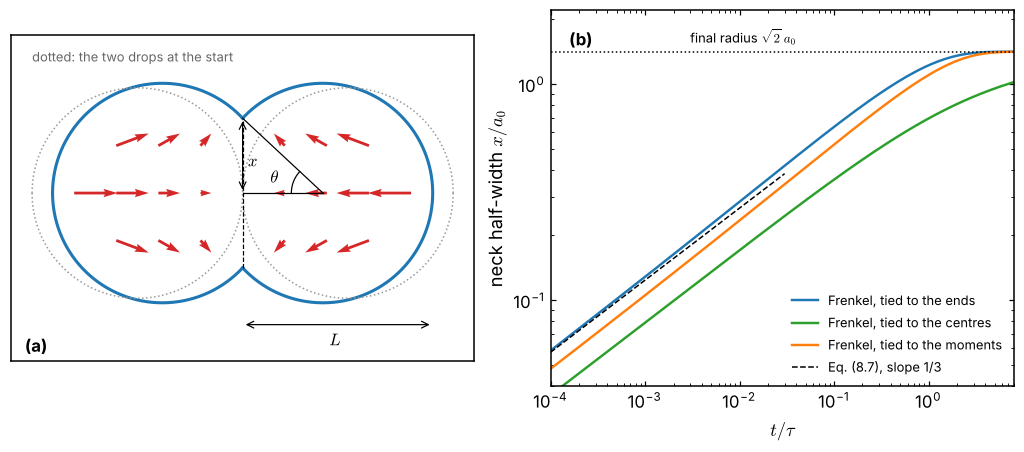

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 4.0))

# (a) Frenkel's shapes and flow
theta0 = 0.75
radius, centre, neck, length, _ = frenkel_geometry(theta0)
for sign in (1, -1):
    phi = np.linspace(-(math.pi - theta0), math.pi - theta0, 200)
    ax1.plot(sign * (centre + radius * np.cos(phi)), radius * np.sin(phi), "C0", lw=2)
    phi = np.linspace(0, 2 * math.pi, 200)
    ax1.plot(sign * (1 + np.cos(phi)), np.sin(phi), color="0.6", ls=":", lw=1)
ax1.fill_between([-length, length], [0, 0], [0, 0])
X, Y = np.meshgrid(np.linspace(-1.6, 1.6, 9), np.linspace(-0.9, 0.9, 5))
inside = ((np.abs(X) - centre) ** 2 + Y**2 < (0.85 * radius) ** 2) & (np.abs(X) > 0.05)
ax1.quiver(X[inside], Y[inside], -0.35 * X[inside], 0.35 * Y[inside], color="C3", scale=6, width=0.006)
ax1.plot([0, 0], [-neck, neck], "k--", lw=0.8)
ax1.annotate("", xy=(0.0, neck), xytext=(0.0, 0.0), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax1.text(0.05, 0.25, "$x$")
ax1.plot([centre, 0], [0, neck], "k-", lw=0.8)
ax1.plot([centre, 0], [0, 0], "k-", lw=0.8)
arc = np.linspace(math.pi - theta0, math.pi, 30)
ax1.plot(centre + 0.3 * np.cos(arc), 0.3 * np.sin(arc), "k-", lw=0.8)
ax1.text(centre - 0.5, 0.1, r"$\theta$")
ax1.annotate("", xy=(length, -1.25), xytext=(0, -1.25), arrowprops=dict(arrowstyle="<->", lw=0.8))
ax1.text(length / 2 - 0.08, -1.45, "$L$")
ax1.text(-2.0, 1.25, "dotted: the two drops at the start", fontsize=8.5, color="0.4")
ax1.set_aspect("equal"); ax1.set_xlim(-2.2, 2.2); ax1.set_ylim(-1.6, 1.5)
ax1.set_xticks([]); ax1.set_yticks([])
on.panel_label(ax1, "(a)", x=0.03, y=0.08)

# (b) the three versions of the model
for (tie, model), color in zip(frenkel.items(), ("C0", "C2", "C1")):
    ax2.loglog(times, model["neck"], color=color, label=f"Frenkel, tied to the {tie}")
tt = np.array([1e-4, 3e-2])
ax2.loglog(tt, (6 * tt / math.pi) ** (1 / 3), "k--", lw=1, label="Eq. (8.7), slope 1/3")
ax2.axhline(math.sqrt(2), color="k", ls=":", lw=1); ax2.text(3e-3, 1.55, r"final radius $\sqrt{2}\,a_0$", fontsize=8.5)
ax2.set_xlabel(r"$t/\tau$"); ax2.set_ylabel("neck half-width $x/a_0$")
ax2.set_xlim(1e-4, 8); ax2.set_ylim(0.04, 2.2)
ax2.legend(loc="lower right", fontsize=8.5); on.panel_label(ax2, "(b)", x=0.04, y=0.95)
plt.show()

**Figure 8.1.** **(a)** Frenkel's model. Each drop keeps the shape of a circle cut
off at the neck, and grows slightly to keep its area; the flow inside (red arrows)
is a uniform compression along the line of centres with an equal extension across
it. **(b)** The neck from Eq. (8.6), with the strain rate tied to the far ends of
the pair (the choice of the text), to the centres of the circles, or to the second
moments of the area. The three versions of the same model disagree.

## 8.3 Check: Hopper's exact solution

For two equal cylinders the Stokes equations with a free surface can be solved
exactly (Hopper, 1984, 1990). At every instant the cross-section is the image of
the unit circle $\lvert\zeta\rvert = 1$ under the map

$$ z = \Omega(\zeta) = C\,\frac{\zeta}{1 + m\zeta^2} , \qquad C = \sqrt2\,a_0\,\frac{1 - m^2}{\sqrt{1 + m^2}} , \tag{8.8} $$

where $z$ is the position in the plane written as a complex number and the
parameter $m$ falls from 1 (two touching circles) to 0 (one circle). The neck has
the half-width $x$ and the pair the half-length $L$,

$$ x = \sqrt2\,a_0\,\frac{1 - m}{\sqrt{1 + m^2}} , \qquad L = \sqrt2\,a_0\,\frac{1 + m}{\sqrt{1 + m^2}} , \tag{8.9} $$

and the parameter is reached at the time

$$ \frac{t}{\tau} = \frac{\pi\sqrt2}{4}\int_{m^2}^1\frac{ds}{s\,(1 + s)^{1/2}K(s)} , \tag{8.10} $$

with $K$ the complete elliptic integral of the first kind (Hopper, 1990). These
formulas are in `on.hopper_time`, `on.hopper_neck`, `on.hopper_length` and
`on.hopper_shape`.

Two limits are useful. At early times the neck grows almost linearly,

$$ x \simeq \frac{\gamma t}{\pi\eta}\,\ln\frac{8a_0}{x} \tag{8.11} $$

(Eggers, Lister and Stone, 1999; Exercise 3). At late times the deformation decays
as $e^{-t/\tau_H}$ with $\tau_H = \eta R_f/\gamma = \sqrt2\,\tau$.

In [6]:
hopper_m = on.hopper_parameter(times)
exact = dict(m=hopper_m, neck=on.hopper_neck(hopper_m), length=on.hopper_length(hopper_m))

def exact_time_at_neck(x):
    return on.hopper_time(brentq(lambda m: on.hopper_neck(m) - x, 0.0, 1.0))

def shrinkage(length):
    """Fraction of the final shortening along the line of centres, from 0 to 1."""
    return (2 - length) / (2 - math.sqrt(2))

print("exact solution:")
for x in (0.1, 0.5, 1.0, 1.3):
    print(f"  neck x = {x:3.1f} a0 at t = {exact_time_at_neck(x):.3f} tau")
for f in (0.5, 0.9):
    m = brentq(lambda m: shrinkage(on.hopper_length(m)) - f, 1e-12, 1 - 1e-12)
    print(f"  {100*f:.0f} % of the shortening at t = {on.hopper_time(m):.3f} tau")
m = 1 - 1e-5
print(f"  early times, Eq. (8.11) at x = {on.hopper_neck(m):.2e}: t = {math.pi * on.hopper_neck(m) / math.log(8 / on.hopper_neck(m)):.3e}"
      f"   exact: {on.hopper_time(m):.3e}")
late = (times > 3) & (times < 7)
print(f"  late times: d ln m / dt = {np.polyfit(times[late], np.log(exact['m'][late]), 1)[0]:.4f}  (-1/sqrt 2 = {-1 / math.sqrt(2):.4f})")

print("\nneck x/a0 at t/tau =                 0.01     0.1      1       4")
print("  exact                           " + "  ".join(f"{v:6.3f}" for v in np.interp([0.01, 0.1, 1, 4], times, exact["neck"])))
print("  Frenkel, tied to the ends       " + "  ".join(f"{v:6.3f}" for v in np.interp([0.01, 0.1, 1, 4], times, frenkel["ends"]["neck"])))
t10 = exact_time_at_neck(0.1)
print(f"\nat t = {t10:.3f} tau, when the exact neck is 0.1 a0:  Frenkel's neck {np.interp(t10, times, frenkel['ends']['neck']):.3f} a0;"
      f"  shortening: exact {shrinkage(on.hopper_length(brentq(lambda m: on.hopper_neck(m) - 0.1, 0, 1))):.4f},"
      f" Frenkel {np.interp(t10, times, shrinkage(frenkel['ends']['length'])):.4f}")
print("fraction of the shortening at t/tau =  0.01     0.1      1       4")
print("  exact                           " + "  ".join(f"{v:6.3f}" for v in np.interp([0.01, 0.1, 1, 4], times, shrinkage(exact["length"]))))
print("  Frenkel, tied to the ends       " + "  ".join(f"{v:6.3f}" for v in np.interp([0.01, 0.1, 1, 4], times, shrinkage(frenkel["ends"]["length"]))))

exact solution:
  neck x = 0.1 a0 at t = 0.060 tau
  neck x = 0.5 a0 at t = 0.462 tau
  neck x = 1.0 a0 at t = 1.445 tau
  neck x = 1.3 a0 at t = 3.156 tau
  50 % of the shortening at t = 1.582 tau
  90 % of the shortening at t = 4.017 tau
  early times, Eq. (8.11) at x = 1.00e-05: t = 2.311e-06   exact: 2.162e-06
  late times: d ln m / dt = -0.7077  (-1/sqrt 2 = -0.7071)

neck x/a0 at t/tau =                 0.01     0.1      1       4
  exact                            0.022   0.152   0.825   1.352
  Frenkel, tied to the ends        0.286   0.634   1.222   1.408

at t = 0.060 tau, when the exact neck is 0.1 a0:  Frenkel's neck 0.534 a0;  shortening: exact 0.0043, Frenkel 0.1994
fraction of the shortening at t/tau =  0.01     0.1      1       4
  exact                            0.000   0.010   0.305   0.898
  Frenkel, tied to the ends        0.062   0.272   0.810   0.993


The model is far from the exact solution. When the exact neck has reached a tenth
of the radius, Frenkel's is more than five times wider, and Frenkel's pair has shortened
about fifty times more than the real one. The two meet only at the end, when
both are close to a circle.

Figure 8.2 shows why. In the exact solution, panel (a), the drops hardly move at
first: the neck fills with liquid drawn from close by. When the neck has reached
half the radius, the pair has shortened by only a tenth of the final amount.

The shapes are not the problem. For the same neck, Frenkel's shapes are close to
the exact ones (panel b). The problem is the flow. In Frenkel's shapes the neck
widens because the two circles overlap more: the liquid in the overlap is removed
and reappears as a slight swelling of the circles. The uniform compression does
not carry out this transfer, so the model never pays for it. In reality the liquid
that fills the neck has to be drawn through the narrow region around it, where the
rates of strain are large.

Panel (c) makes this quantitative. It shows the friction against the growth of the
neck, $\zeta_x = -\gamma\,(dP/dx)/\dot x$, the force that drives the neck divided by
its speed. For Frenkel's model this friction vanishes as $2\pi\eta\,(x/a_0)^2$ for a
small neck, because a tiny compression produces a large widening of the overlap.
The exact friction falls only as $4\pi\eta/\ln(8a_0/x)$, from Eq. (8.11) and the
driving force $4\gamma$. A model that does not pay for the flow that fills the neck
lets the neck grow far too quickly. No choice of tie in Eq. (8.5) can mend this.
The fault is that the flow does not produce the shapes.

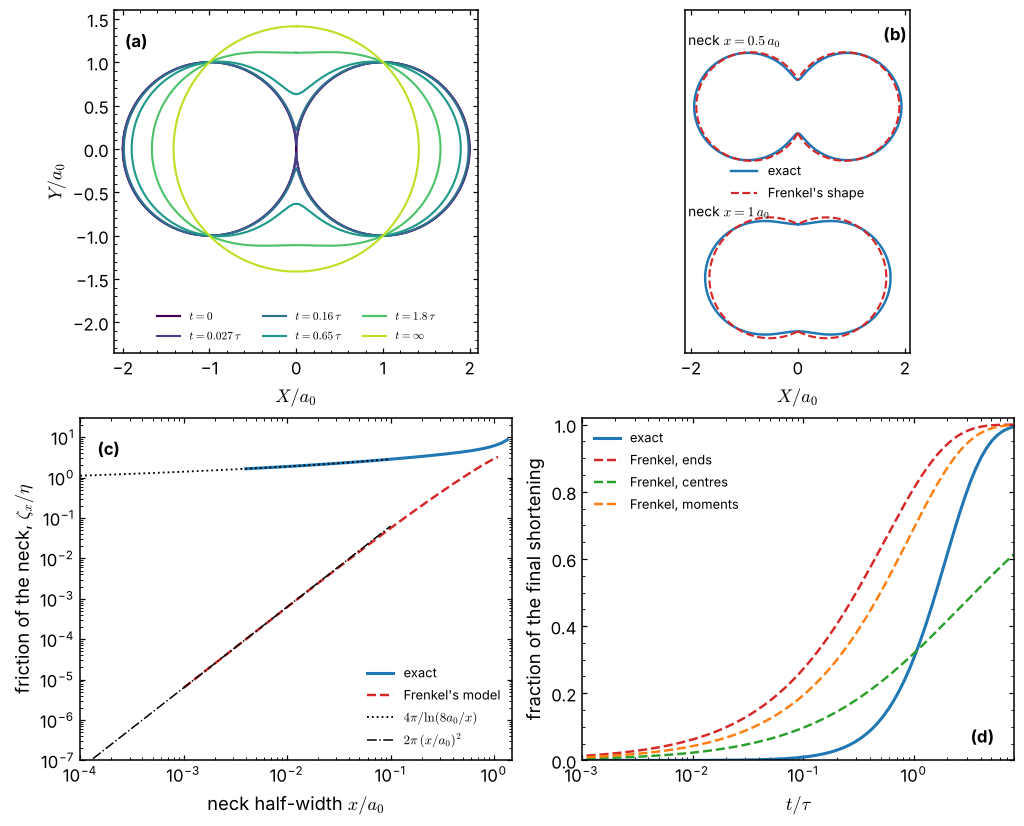

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
shown = [1.0, 0.95, 0.8, 0.5, 0.2, 0.0]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(shown)))
for m, color in zip(shown, colors):
    if m == 1.0:
        phi = np.linspace(0, 2 * math.pi, 300)
        X = np.concatenate((1 + np.cos(phi), [np.nan], -1 - np.cos(phi)))
        Y = np.concatenate((np.sin(phi), [np.nan], np.sin(phi)))
        label = r"$t = 0$"
    else:
        X, Y = on.hopper_shape(m, n=4001)
        label = r"$t = \infty$" if m == 0 else rf"$t = {on.hopper_time(m):.2g}\,\tau$"
    ax.plot(X, Y, color=color, lw=1.4, label=label)
ax.set_aspect("equal"); ax.set_xlim(-2.1, 2.1); ax.set_ylim(-2.35, 1.6)
ax.set_xlabel("$X/a_0$"); ax.set_ylabel("$Y/a_0$")
ax.legend(loc="lower center", fontsize=7.5, ncol=3, frameon=False)
on.panel_label(ax, "(a)", x=0.03, y=0.94)

ax = axes[0, 1]
for x_neck, offset in ((0.5, 1.6), (1.0, -1.6)):
    m = brentq(lambda m: on.hopper_neck(m) - x_neck, 0.0, 1.0)
    X, Y = on.hopper_shape(m, n=4001)
    ax.plot(X, Y + offset, "C0", lw=1.6, label="exact" if offset > 0 else None)
    theta = brentq(lambda s: frenkel_geometry(s)[2] - x_neck, 1e-9, math.pi / 2)
    radius, centre = frenkel_geometry(theta)[:2]
    for sign in (1, -1):
        phi = np.linspace(-(math.pi - theta), math.pi - theta, 200)
        ax.plot(sign * (centre + radius * np.cos(phi)), radius * np.sin(phi) + offset, "C3--", lw=1.4,
                label="Frenkel's shape" if (sign == 1 and offset > 0) else None)
    ax.text(-2.05, offset + 1.15, f"neck $x = {x_neck:g}\\,a_0$", fontsize=9)
ax.set_aspect("equal"); ax.set_xlim(-2.1, 2.1); ax.set_ylim(-3.0, 3.4)
ax.set_xlabel("$X/a_0$"); ax.set_yticks([])
ax.legend(loc="center", fontsize=8.5, frameon=False); on.panel_label(ax, "(b)", x=0.88, y=0.96)

ax = axes[1, 0]
# friction against the growth of the neck, zeta_x = -gamma (dP/dx) / xdot, in units of eta
ms = 1 - np.logspace(-2.4, -0.02, 50)            # the perimeter is not resolved for a thinner neck
dx_dm = np.array([derivative(on.hopper_neck, m, 1e-8) for m in ms])
minus_dt_dm = np.array([math.pi * math.sqrt(2) / 4 * 2 / (m * math.sqrt(1 + m * m) * ellipk(m * m)) for m in ms])
dP_dm = np.array([derivative(on.hopper_perimeter, m, 1e-7) for m in ms])
ax.loglog(on.hopper_neck(ms), dP_dm * minus_dt_dm / dx_dm**2, "C0", lw=2, label="exact")
thetas = np.logspace(-3, math.log10(1.2), 80)
zeta_frenkel = [-derivative(lambda s: frenkel_geometry(s)[4], s)
                / (frenkel_rate(s, "ends") * derivative(lambda s: frenkel_geometry(s)[2], s) ** 2) for s in thetas]
ax.loglog([frenkel_geometry(s)[2] for s in thetas], zeta_frenkel, "C3--", lw=1.6, label="Frenkel's model")
xx = np.logspace(-4, -1, 20)
ax.loglog(xx, 4 * math.pi / np.log(8 / xx), "k:", lw=1.2, label=r"$4\pi/\ln(8a_0/x)$")
ax.loglog(xx, 2 * math.pi * xx**2, "k-.", lw=1, label=r"$2\pi\,(x/a_0)^2$")
ax.set_xlabel("neck half-width $x/a_0$"); ax.set_ylabel(r"friction of the neck, $\zeta_x/\eta$")
ax.set_xlim(1e-4, 1.5); ax.set_ylim(1e-7, 30)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(c)", x=0.04, y=0.94)

ax = axes[1, 1]
ax.semilogx(times, shrinkage(exact["length"]), "C0", lw=2, label="exact")
for (tie, model), color in zip(frenkel.items(), ("C3", "C2", "C1")):
    ax.semilogx(times, shrinkage(model["length"]), "--", color=color, label=f"Frenkel, {tie}")
ax.set_xlabel(r"$t/\tau$"); ax.set_ylabel("fraction of the final shortening")
ax.set_xlim(1e-3, 8); ax.set_ylim(0, 1.02)
ax.legend(loc="upper left", fontsize=8.5); on.panel_label(ax, "(d)", x=0.9, y=0.1)
plt.show()

**Figure 8.2.** Check of Frenkel's model against Hopper's exact solution. **(a)** The
exact shapes. The neck fills first, and the pair shortens later. **(b)** Exact
shapes and Frenkel's shapes with the same neck width: they are close. **(c)** The
friction against the growth of the neck, $\zeta_x = -\gamma\,(dP/dx)/\dot x$. In
Frenkel's model it vanishes as $x^2$; the exact one falls only as $1/\ln(8a_0/x)$.
**(d)** The shortening against time. All three versions of Frenkel's model shorten
the pair far too early.

## 8.4 A trial that fits: the right shapes and the simplest flow

The lesson of Section 8.3 is that the flow must do the work of changing the shape.
The safe way to ensure this is to choose the shapes first and then compute a flow
that moves them. We take the exact shapes of Eq. (8.8), with $m$ as the slow
variable, so that any error comes from the flow alone, and ask for a flow. It must be incompressible and must move the boundary as the shapes require:
its velocity normal to the boundary must equal the normal velocity $V_n$ of the
boundary when $m$ changes at the rate $\dot m$.

The simplest such flow has no rotation. Its velocity is the gradient of a potential,
$\mathbf v = \nabla\phi$, with

$$ \nabla^2\phi = 0 \ \text{inside}, \qquad \frac{\partial\phi}{\partial n} = V_n = \frac{\partial\mathbf r}{\partial m}\cdot\mathbf n\;\dot m \ \text{on the boundary}. \tag{8.12} $$

This problem has one solution for each shape, and it is proportional to $\dot m$.
Its dissipation function is $\Phi = \eta\int(\partial_i\partial_j\phi)^2\,dA = \tfrac12\zeta_{\rm pot}(m)\,\dot m^2$.
Minimising $\Phi + \gamma\,(dP/dm)\,\dot m$ gives

$$ \dot m = -\frac{\gamma\,dP/dm}{\zeta_{\rm pot}(m)} . \tag{8.13} $$

*A guaranteed direction.* Of all incompressible flows with the same normal velocity
on the boundary, the Stokes flow dissipates least (Section 1.3; the free boundary
adds only the condition that the shear stress vanish there, which the minimum
supplies by itself; Exercise 2). The exact solution moves through the same shapes,
so at every $m$ its friction is smaller than or equal to $\zeta_{\rm pot}(m)$,
while the driving force $-\gamma\,dP/dm$ is the same. *The trial solution is
therefore slower than the exact one at every stage*, and it reaches every neck width
later. This is the minimum principle of Chapter 1 at work. Frenkel's model has no
such property, because its flow does not produce its shapes.

*Computing the flow.* The map (8.8) turns Eq. (8.12) into a problem on the unit
disc, where it is solved by a Fourier series. In complex notation the flow is
$v_X - i v_Y = dW/dz$, with $W(z) = F(\zeta)$ analytic, and the boundary condition
reads $\mathrm{Re}[\zeta F'(\zeta)] = \mathrm{Re}[\overline{\zeta\Omega'(\zeta)}\,\partial\Omega/\partial m]\,\dot m$
on $\lvert\zeta\rvert = 1$. The Fourier coefficients of the right-hand side are the
Taylor coefficients of $\zeta F'$. The rate of strain is $W''(z)$, and the
dissipation $\Phi = 2\eta\int\lvert W''\rvert^2 dA$ is a sum over the Taylor
coefficients of the analytic function $W''(z)\,\Omega'(\zeta)$, since
$\int_{\lvert\zeta\rvert<1}\lvert\sum_k h_k\zeta^k\rvert^2 dA = \pi\sum_k\lvert h_k\rvert^2/(k + 1)$.
The cell below does this with fast Fourier transforms; the exact friction for
comparison follows from Eq. (8.10) as $\zeta_{\rm exact} = \gamma\,(dP/dm)\,(dt/dm)$.

In [8]:
N_FFT = 1 << 14
zeta = np.exp(2j * np.pi * np.arange(N_FFT) / N_FFT)       # points on the unit circle

def hopper_map(z, m):
    C = math.sqrt(2) * (1 - m * m) / math.sqrt(1 + m * m)
    return C * z / (1 + m * z * z), C * (1 - m * z * z) / (1 + m * z * z) ** 2, C * 2 * m * z * (m * z * z - 3) / (1 + m * z * z) ** 3

def perimeter(m):
    return 2 * math.pi * np.mean(np.abs(hopper_map(zeta, m)[1]))

def potential_flow(m, h=1e-7):
    """Taylor coefficients b_k (k = 1, 2, ...) of zeta F'(zeta) for mdot = 1, Eq. (8.12)."""
    dOmega_dm = (hopper_map(zeta, m + h)[0] - hopper_map(zeta, m - h)[0]) / (2 * h)
    boundary = np.real(dOmega_dm * np.conj(zeta * hopper_map(zeta, m)[1]))
    return 2 * (np.fft.fft(boundary) / N_FFT)[1:N_FFT // 2]

def friction_potential(m):
    """zeta_pot(m) = 2 Phi / mdot^2 for the potential flow (eta = 1, a0 = 1)."""
    b = potential_flow(m)
    k = np.arange(1, N_FFT // 2)
    F1 = np.zeros(N_FFT, complex); F1[:N_FFT // 2 - 1] = b                 # F'  = sum b_k zeta^(k-1)
    F2 = np.zeros(N_FFT, complex); F2[:N_FFT // 2 - 2] = (k[1:] - 1) * b[1:]   # F'' = sum (k-1) b_k zeta^(k-2)
    F1, F2 = np.fft.ifft(F1) * N_FFT, np.fft.ifft(F2) * N_FFT
    _, d1, d2 = hopper_map(zeta, m)
    h = (np.fft.fft((F2 * d1 - F1 * d2) / d1**2) / N_FFT)[:N_FFT // 2]   # W''(z) Omega'(zeta)
    return 4 * math.pi * np.sum(np.abs(h) ** 2 / (np.arange(N_FFT // 2) + 1))

def friction_exact(m):
    dt_dm = math.pi * math.sqrt(2) / 4 * 2 / (m * math.sqrt(1 + m * m) * ellipk(m * m))   # -dt/dm, Eq. (8.10)
    return derivative(perimeter, m) * dt_dm

print("    m     neck x/a0   zeta_pot   zeta_exact   ratio")
for m in (0.99, 0.9, 0.7, 0.5, 0.3, 0.1, 0.001):
    print(f"  {m:5.3f}    {on.hopper_neck(m):6.3f}    {friction_potential(m):8.4f}   {friction_exact(m):8.4f}    {friction_potential(m)/friction_exact(m):.4f}")
print(f"\nperimeter of the final circle: {perimeter(0.0):.6f}  (2 sqrt2 pi = {2*math.sqrt(2)*math.pi:.6f})")

    m     neck x/a0   zeta_pot   zeta_exact   ratio
  0.990     0.010      6.4013     1.9189    3.3358
  0.900     0.105      7.6715     3.5040    2.1894
  0.700     0.348     11.3205     6.7508    1.6769
  0.500     0.632     16.0850    10.8778    1.4787
  0.300     0.948     21.1537    15.3214    1.3807
  0.100     1.266     24.6375    18.4087    1.3384
  0.001     1.413     25.1327    18.8495    1.3333

perimeter of the final circle: 8.885766  (2 sqrt2 pi = 8.885766)


The friction of the potential flow is larger than the exact one for every shape,
as it must be. Near the end the ratio is exactly $4/3$. There the shape is a
slightly deformed circle, the potential flow is a uniform extension, and the exact
flow adds a rotational part that removes the shear stress at the surface
(Exercise 2). Earlier the ratio grows: 1.5 when the neck is half the radius, 2.2
when it is a tenth, and more for a thinner neck. The narrower the neck, the more
the exact flow differs from a flow without rotation.

The cell below integrates Eq. (8.13). It starts from the exact shape whose neck is
1 % of the radius, at the exact time for that shape.

In [9]:
m_start = brentq(lambda m: on.hopper_neck(m) - 0.01, 0.5, 1.0)
t_start = on.hopper_time(m_start)
potential = solve_ivp(lambda t, y: [-derivative(perimeter, y[0]) / friction_potential(y[0])],
                      (t_start, times[-1]), [m_start], t_eval=times[times >= t_start], rtol=1e-8, atol=1e-12)
pot = dict(t=potential.t, m=potential.y[0], neck=on.hopper_neck(potential.y[0]), length=on.hopper_length(potential.y[0]))

print("time to reach a neck x (in units of tau)")
print("   x/a0     exact    potential flow   ratio    Frenkel (ends)   ratio")
for x in (0.05, 0.1, 0.3, 0.5, 1.0, 1.3):
    te = exact_time_at_neck(x)
    tp = np.interp(x, pot["neck"], pot["t"])
    tf = np.interp(x, frenkel["ends"]["neck"], times)
    print(f"   {x:4.2f}    {te:6.3f}       {tp:6.3f}        {tp/te:5.2f}       {tf:7.4f}       {tf/te:5.3f}")
late = (pot["t"] > 3) & (pot["t"] < 7)
print(f"\nlate decay rate of m: potential flow {np.polyfit(pot['t'][late], np.log(pot['m'][late]), 1)[0]:.4f},"
      f" exact {-1/math.sqrt(2):.4f};  ratio {np.polyfit(pot['t'][late], np.log(pot['m'][late]), 1)[0] * -math.sqrt(2):.4f} = 3/4")

time to reach a neck x (in units of tau)
   x/a0     exact    potential flow   ratio    Frenkel (ends)   ratio
   0.05     0.026        0.067         2.54        0.0001       0.002
   0.10     0.060        0.146         2.44        0.0005       0.008
   0.30     0.233        0.477         2.05        0.0115       0.049
   0.50     0.462        0.850         1.84        0.0497       0.108
   1.00     1.445        2.257         1.56        0.4317       0.299
   1.30     3.156        4.564         1.45        1.4339       0.454

late decay rate of m: potential flow -0.5317, exact -0.7071;  ratio 0.7519 = 3/4


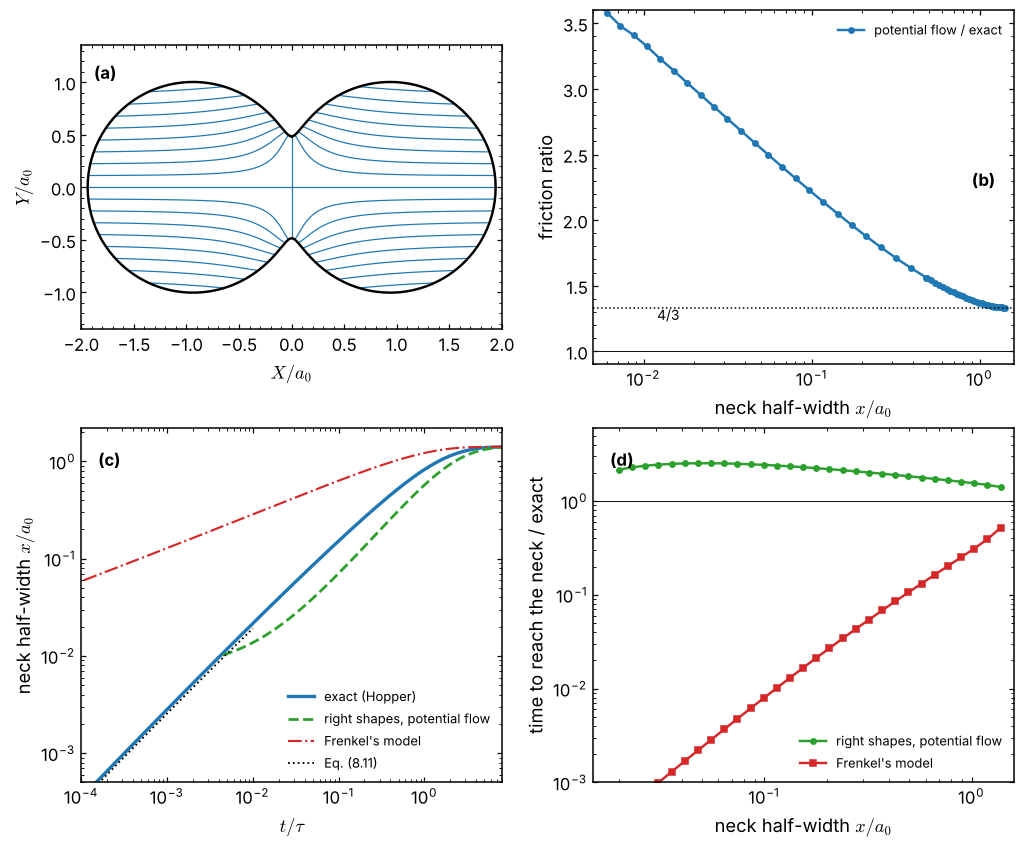

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.6))

ax = axes[0, 0]
m_show = 0.6
b = potential_flow(m_show)
k = np.arange(1, N_FFT // 2)
rr, aa = np.meshgrid(np.linspace(0, 1, 120), np.linspace(0, 2 * math.pi, 361))
zz = rr * np.exp(1j * aa)
F = np.polynomial.polynomial.polyval(zz, np.concatenate(([0], b[:200] / k[:200])))       # F = sum b_k zeta^k / k
pos = 1j * hopper_map(zz, m_show)[0]                                                      # rotate: line of centres along X
ax.contour(pos.real, pos.imag, F.imag, levels=21, colors="C0", linewidths=0.8, linestyles="solid")
X, Y = on.hopper_shape(m_show)
ax.plot(X, Y, "k", lw=1.6)
ax.set_aspect("equal"); ax.set_xlim(-2.0, 2.0); ax.set_ylim(-1.35, 1.35)
ax.set_xlabel("$X/a_0$"); ax.set_ylabel("$Y/a_0$")
on.panel_label(ax, "(a)", x=0.03, y=0.94)

ax = axes[0, 1]
m_grid = np.concatenate((1 - np.logspace(-2.3, -0.4, 25), np.linspace(0.6, 0.002, 30)))
ratio = np.array([friction_potential(m) / friction_exact(m) for m in m_grid])
ax.semilogx(on.hopper_neck(m_grid), ratio, "C0o-", ms=3.5, label="potential flow / exact")
ax.axhline(4 / 3, color="k", ls=":", lw=1); ax.text(0.012, 1.24, "4/3", fontsize=9)
ax.axhline(1, color="k", lw=0.6)
ax.set_xlabel("neck half-width $x/a_0$"); ax.set_ylabel("friction ratio")
ax.set_xlim(5e-3, 1.6); ax.set_ylim(0.9, 3.6)
ax.legend(loc="upper right", fontsize=8.5); on.panel_label(ax, "(b)", x=0.9, y=0.55)

ax = axes[1, 0]
ax.loglog(times, exact["neck"], "C0", lw=2.2, label="exact (Hopper)")
ax.loglog(pot["t"], pot["neck"], "C2--", lw=1.8, label="right shapes, potential flow")
ax.loglog(times, frenkel["ends"]["neck"], "C3-.", lw=1.4, label="Frenkel's model")
tt = np.logspace(-4, -2, 20)
xx = np.array([brentq(lambda x: x - t / math.pi * math.log(8 / x), 1e-12, 1.0) for t in tt])
ax.loglog(tt, xx, "k:", lw=1.2, label="Eq. (8.11)")
ax.set_xlabel(r"$t/\tau$"); ax.set_ylabel("neck half-width $x/a_0$")
ax.set_xlim(1e-4, 8); ax.set_ylim(5e-4, 2.2)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(c)", x=0.04, y=0.94)

ax = axes[1, 1]
necks = np.logspace(-1.7, math.log10(1.38), 30)
t_exact = np.array([exact_time_at_neck(x) for x in necks])
ax.semilogx(necks, np.interp(necks, pot["neck"], pot["t"]) / t_exact, "C2o-", ms=3.5, label="right shapes, potential flow")
ax.semilogx(necks, np.interp(necks, frenkel["ends"]["neck"], times) / t_exact, "C3s-", ms=3.5, label="Frenkel's model")
ax.axhline(1, color="k", lw=0.6)
ax.set_yscale("log")
ax.set_xlabel("neck half-width $x/a_0$"); ax.set_ylabel("time to reach the neck / exact")
ax.set_xlim(0.015, 1.6); ax.set_ylim(1e-3, 6)
ax.legend(loc="lower right", fontsize=8.5); on.panel_label(ax, "(d)", x=0.04, y=0.94)
plt.show()

**Figure 8.3.** Check of the trial with the right shapes. **(a)** Streamlines of the
potential flow inside the exact shape with $m = 0.6$ (neck $x = 0.48\,a_0$): liquid
moves from the far ends towards the neck. **(b)** Friction of the potential flow
divided by the exact friction, for the same shape. It is never below 1, as the
minimum principle requires, and it tends to $4/3$ as the drop becomes round.
**(c)** Neck against time. The trial with the right shapes (started from the exact
state at $x = 0.01\,a_0$) lags behind the exact solution. Frenkel's model runs
ahead. **(d)** Time to reach a given neck, divided by the exact time: always above
1 for the potential flow, and far below 1 for Frenkel's model at small necks.

## 8.5 What to trust

The two trial solutions err in opposite directions, and for different reasons.

*Frenkel's model* gives the right time scale, $\tau = \eta a_0/\gamma$, and the right
final state. Its early law $x \propto t^{1/3}$ (and $x \propto t^{1/2}$ for spheres,
Exercise 1) is wrong, because its flow does not produce its shapes: the liquid that
fills the neck is moved at no cost, whereas in the real process it is drawn through
the narrow region around the neck, at a large rate of strain. Nothing in the model warns of this,
except that it can be completed in several ways that disagree. Its numbers should
be read as estimates of the order of magnitude. When it fits measurements, as it
often does for polymer powders, the fit tells us about the fitted parameter more
than about the model.

*The trial with the right shapes and a potential flow* is consistent. Its error has
a known sign: it is slower than the exact solution. Over the whole process the
time to reach a given neck is too long by a factor between 1.4 and about 2.5. The
missing piece is the rotation of the exact flow, which matters most where the
boundary is most curved, at a narrow neck.

The general lesson, for any problem with a free boundary: a trial solution is a
family of shapes *together with* a flow that moves one shape of the family into the
next. When the flow fits the shapes, the minimum principle bounds the error of the
friction from one side. When it does not, the result can be wrong in either
direction and by any amount.

## Summary

* Two viscous drops coalesce on the time scale $\tau = \eta a_0/\gamma$, driven by
  the decrease of their surface and resisted by viscous flow inside them.
* Frenkel's model uses truncated circles (or spheres) and a uniform compression.
  The flow cannot produce the shapes, so it must be tied to them somewhere, and
  different ties give different answers. Its early law, $x \propto t^{1/3}$ for
  cylinders, is wrong.
* Hopper's exact solution for two cylinders shows that the neck first fills by a
  local flow, $x \simeq (\gamma t/\pi\eta)\ln(8a_0/x)$, while the drops hardly move.
  Frenkel's shapes are close to the exact ones; his flow is not, and it leaves the
  filling of the neck without friction.
* With the exact shapes and a potential flow, the trial is consistent and the
  minimum principle guarantees that it is slower than the exact solution. It is
  1.4 to 2.5 times too slow; the friction ratio is $4/3$ near the end, where a
  rotational flow removes the difference (Exercise 2).
* A trial solution for a free-boundary problem must consist of shapes and a flow
  that carries them.

## Exercises

Sample solutions are in [`solutions/part2_liquids_interfaces/08_solutions.ipynb`](../../solutions/part2_liquids_interfaces/08_solutions.ipynb).

1. **Two spheres.** Repeat Frenkel's model for two spheres of radius $a_0$: truncated
   spheres, and a uniform axial compression ($v_z = \dot\epsilon z$,
   $v_r = -\tfrac12\dot\epsilon r$, dissipation $3\eta\dot\epsilon^2$ per unit volume).
   (a) Tie the strain rate to the far ends and show that $x^2 = 4\,a_0\gamma t/\eta$
   for a small neck; tie it to the centres and show that $x^2 = a_0\gamma t/\eta$.
   Frenkel's law is usually quoted as $x^2 = \tfrac32\,a_0\gamma t/\eta$. (b) Show
   that the version tied to the far ends has the same dependence on $\theta$ as the
   equation of Pokluda, Bellehumeur and Vlachopoulos (1997), with a rate four times
   larger. (c) Integrate to the final sphere of radius $2^{1/3}a_0$.
2. **The last stage.** A cylinder of radius $R$ has the slightly deformed
   cross-section $r = R(1 + \varepsilon\cos2\varphi)$. (a) Show that the excess
   perimeter at fixed area is $\tfrac32\pi R\varepsilon^2$. (b) With the uniform
   extension, stream function $\psi = AR^{-1}r^2\sin2\varphi$, show that
   $\dot\varepsilon = -3\gamma\varepsilon/4\eta R$. (c) Add the rotational term
   $BR^{-3}r^4\sin2\varphi$, minimise over $B$ at fixed $\dot\varepsilon$ and show that
   $\dot\varepsilon = -\gamma\varepsilon/\eta R$, which is the late-time rate of
   Hopper's solution. Show that the shear stress at the surface vanishes for the
   optimal $B$, although it was not imposed.
3. **The early neck.** Near $s = 1$, $K(s) \simeq \tfrac12\ln[16/(1 - s)]$. Use this
   in Eq. (8.10) to derive Eq. (8.11), and compare the two numerically. What sets
   the factor 8 inside the logarithm? Why does the neck grow almost linearly in
   time, while every trial with a uniform strain gives a power smaller than 1?
4. **Sintering in practice.** (a) For the two materials of Section 8.1, find from
   the exact solution the time for the neck to reach half the radius and for 90 % of
   the shortening. (b) Estimate the Reynolds number $\rho\,(a_0/\tau)\,a_0/\eta$ and
   show that inertia is negligible for both. Down to which viscosity would that
   remain true for a water-like density and $a_0 = 1$ mm? (c) Compare the times
   with those of Frenkel's model.

## Suggested references

* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* G. K. Batchelor, *An Introduction to Fluid Dynamics* (Cambridge University Press, 1967).
* J. Frenkel, "Viscous flow of crystalline bodies under the action of surface tension", *J. Phys. (USSR)* **9**, 385 (1945).
* R. W. Hopper, "Coalescence of two equal cylinders: exact results for creeping viscous plane flow driven by capillarity", *J. Am. Ceram. Soc.* **67**, C262 (1984).
* R. W. Hopper, "Plane Stokes flow driven by capillarity on a free surface", *J. Fluid Mech.* **213**, 349 (1990).
* J. Eggers, J. R. Lister and H. A. Stone, "Coalescence of liquid drops", *J. Fluid Mech.* **401**, 293 (1999).
* O. Pokluda, C. T. Bellehumeur and J. Vlachopoulos, "Modification of Frenkel's model for sintering", *AIChE J.* **43**, 3253 (1997).

---

**Previous:** [7. Spreading of a droplet](07_spreading_droplet.ipynb) &nbsp;·&nbsp; **Next:** [9. A drying droplet](09_drying_droplet.ipynb)